# Question 1

Load the data from the file *trajectory.csv*. The data consists of three rows representing a trajectory. The first row represents time, the second row represents the $x$-coordinate at each timestep, and the third row represents the $y$-coordinate.

**Q1 a (3 marks)**

Plot the $x$-coordinate against time (i.e., t-x figure) and also for the $y$-coordinate (i.e., t-y figure). Also plot the trajectory in 2D (i.e., x-y figure).

You need to respectively use variables 't', 'x', 'y' to represent time, x-coordinate, and y-coordinate, as these variables will be needed in other questions.

Include clear titles, axis labels, and legends for all figures.

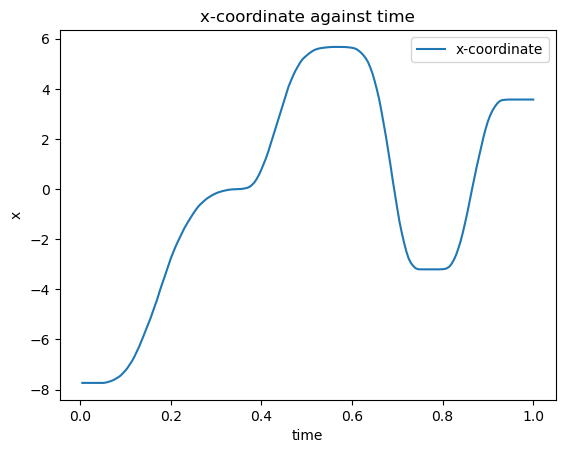

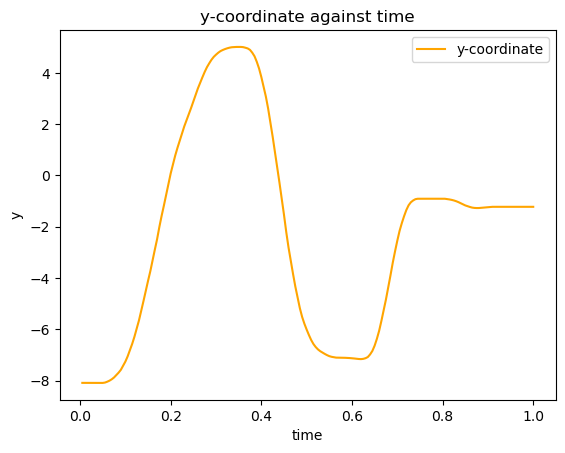

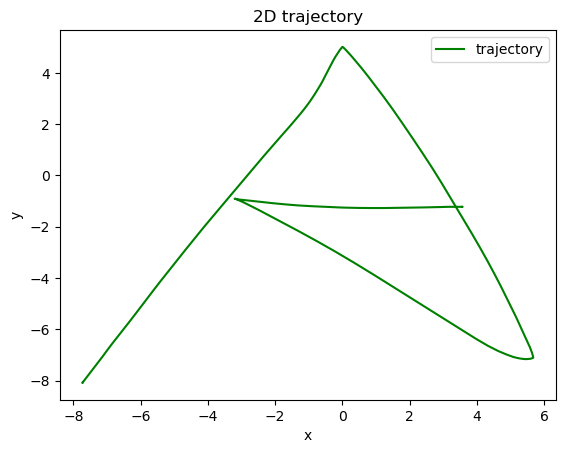

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# read from trajectory.csv
data = np.loadtxt("trajectory.csv", delimiter=",", skiprows=1, usecols=range(1, 201))
t = data[0]
x = data[1]
y = data[2]


# TODO: write your code here.
plt.figure()
plt.plot(t, x, label="x-coordinate")
plt.title("x-coordinate against time")
plt.xlabel("time")
plt.ylabel("x")
plt.legend()

plt.figure()
plt.plot(t, y, label="y-coordinate", color="orange")
plt.title("y-coordinate against time")
plt.xlabel("time")
plt.ylabel("y")
plt.legend()

plt.figure()
plt.plot(x, y, label="trajectory", color="green")
plt.title("2D trajectory")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()


### Linear regression using polynomial basis functions

**Q1 b (6 marks)**

Use your `t`, `x`, and `y` variables from Q1 a.

1. Implement `polynomial_basis_function(t, basis_num)` to return a polynomial design matrix.
2. Use linear regression with your basis function (for Q1 b, use `basis_num = 15`) to fit the 2D trajectory data (`x`, `y`). Note that the bias term should be added in your fitting.
3. Generate predicted trajectories for both coordinates across all time points.
4. Plot and compare on the same axes:
   - original `x` and predicted `x` against `t`,
   - original `y` and predicted `y` against `t`,
   - original and predicted trajectories in the `x-y` plane.

Include clear titles, axis labels, and legends for all figures.

Polynomial design matrix shape: (200, 15)
Design matrix with bias shape: (200, 16)


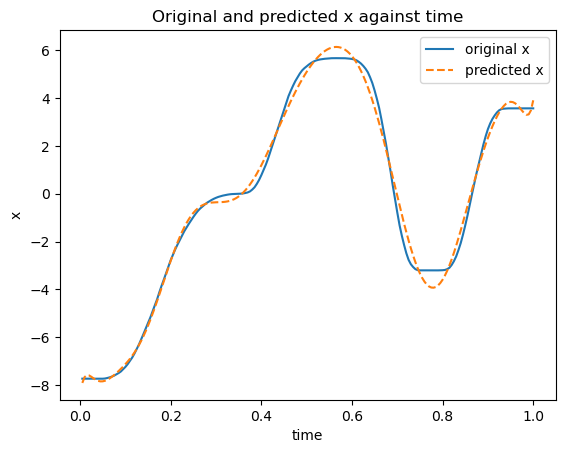

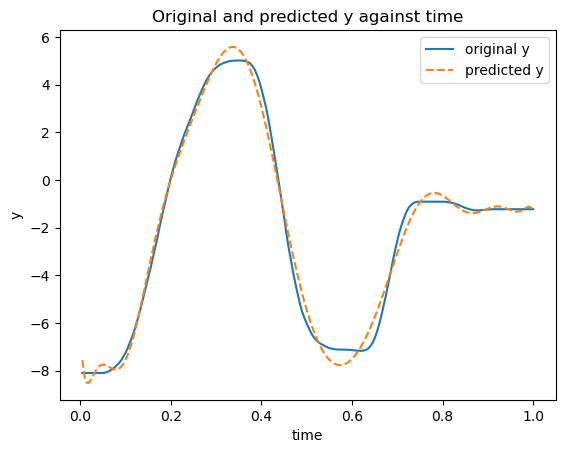

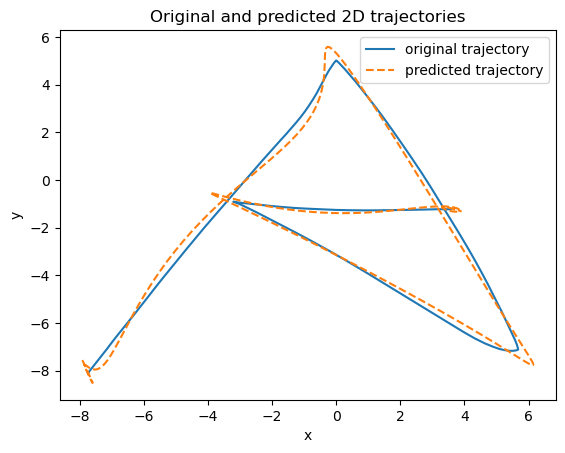

In [2]:
# TODO: Write your code here.
def polynomial_basis_function(t, basis_num):
    """
    Compute the polynomial basis function for the given time vector and number of basis functions.

    Parameters:
    t (numpy array): Time vector of shape (N,).
    basis_num (int): Number of polynomial basis functions.

    Returns:
    numpy array: Design matrix of shape (N, basis_num) where each row corresponds to one data sample.
    """
    t = np.asarray(t).reshape(-1)
    return np.column_stack([t ** power for power in range(1, basis_num + 1)])
    

# TODO: Write your code here.
basis_num = 15
phi = polynomial_basis_function(t, basis_num)
design_matrix = np.column_stack([np.ones_like(t), phi])

# Fit x and y separately using the same design matrix.
w_x = np.linalg.lstsq(design_matrix, x, rcond=None)[0]
w_y = np.linalg.lstsq(design_matrix, y, rcond=None)[0]

x_pred = design_matrix @ w_x
y_pred = design_matrix @ w_y

print("Polynomial design matrix shape:", phi.shape)
print("Design matrix with bias shape:", design_matrix.shape)

plt.figure()
plt.plot(t, x, label="original x")
plt.plot(t, x_pred, label="predicted x", linestyle="--")
plt.title("Original and predicted x against time")
plt.xlabel("time")
plt.ylabel("x")
plt.legend()

plt.figure()
plt.plot(t, y, label="original y")
plt.plot(t, y_pred, label="predicted y", linestyle="--")
plt.title("Original and predicted y against time")
plt.xlabel("time")
plt.ylabel("y")
plt.legend()

plt.figure()
plt.plot(x, y, label="original trajectory")
plt.plot(x_pred, y_pred, label="predicted trajectory", linestyle="--")
plt.title("Original and predicted 2D trajectories")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()


**Q1 c (3 marks)**

Using the polynomial basis model, plot the fitted trajectories for `basis_num = 2, 5, 10` and briefly compare how fit quality changes as the number of basis functions increases.

Include clear titles, axis labels, and legends for all figures.

As basis_num increases from 2 to 10, the fitted trajectory follows the original data more closely.


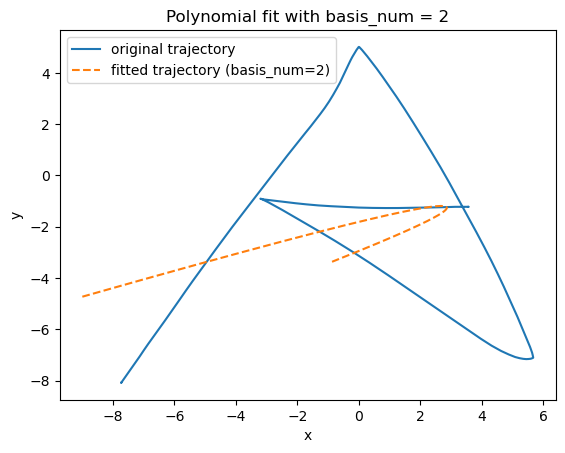

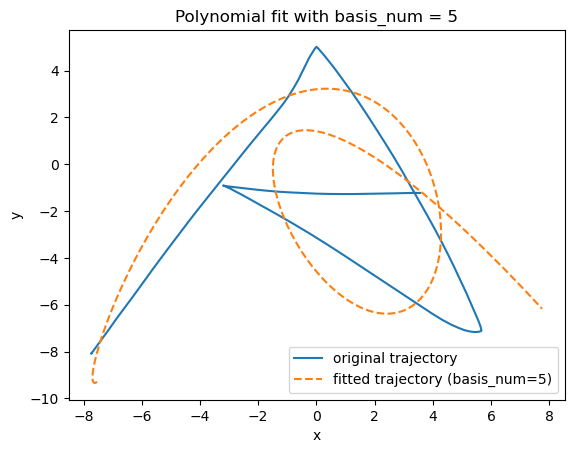

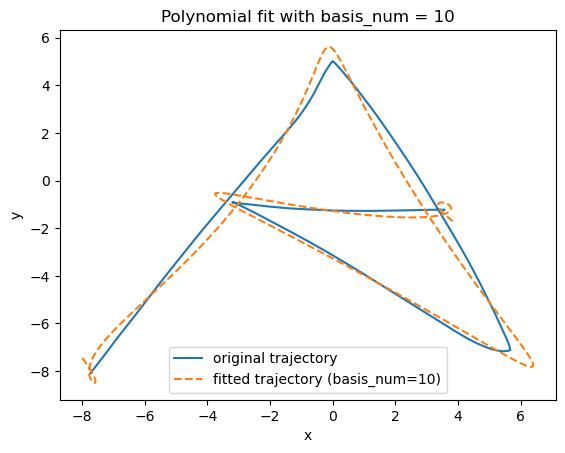

In [3]:
# TODO: Write your code here.
for basis_num in [2, 5, 10]:
    phi = polynomial_basis_function(t, basis_num)
    design_matrix = np.column_stack([np.ones_like(t), phi])
    x_pred = design_matrix @ np.linalg.lstsq(design_matrix, x, rcond=None)[0]
    y_pred = design_matrix @ np.linalg.lstsq(design_matrix, y, rcond=None)[0]

    plt.figure()
    plt.plot(x, y, label="original trajectory")
    plt.plot(x_pred, y_pred, label=f"fitted trajectory (basis_num={basis_num})", linestyle="--")
    plt.title(f"Polynomial fit with basis_num = {basis_num}")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()

print("As basis_num increases from 2 to 10, the fitted trajectory follows the original data more closely.")
plt.show()


# Question 2

Given a set of basis functions (sine, cosine, exponential, polynomial, and radial basis functions), select and combine appropriate ones to construct a suitable basis function vector for linear regression.

Find the smallest number of basis functions that provides a good fit to the following trajectories.

**Q2 a (5 marks)**

Consider what basis functions might be suitable to model the data in "q2_a_data.npy". In this file, the first column is time t while the second column is the x-coordinate. You should be able to achieve a good fit with a small number of basis functions.

Tasks:
1. Choose and implement your basis function combination. You may decide whether to include a bias term depending on your fitting performance.
2. Plot your prediction and the original data in the same figure (i.e., t-x).
3. Calculate and report the Mean Squared Error (MSE) for your fit.
4. Justify your choice of basis functions.

Include clear titles, axis labels, and legends for all figures.


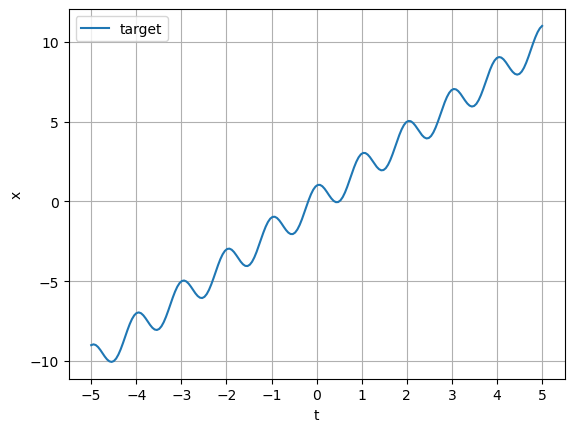

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

#  plot the trajectory
data = np.load("q2_a_data.npy") # size: 200*2, the first column is time input while the second column is x-coordinate.
t = data[:, 0]
target = data[:, 1]

plt.plot(t, target, label='target')
ax = plt.gca()
ax.xaxis.set_major_locator(MultipleLocator(1))  # tick interval = 1
plt.legend()
plt.grid()
plt.xlabel("t")
plt.ylabel("x")
plt.show()

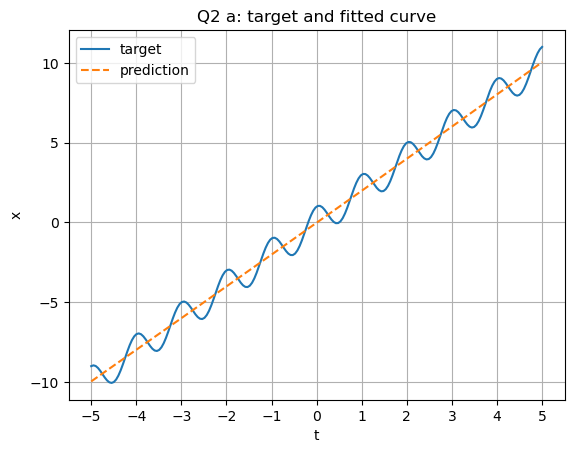

MSE: 0.502159
Justification: A quadratic polynomial is enough here because the curve follows a smooth parabolic trend with no clear periodic behaviour.


In [5]:
# TODO: Write your code here.
phi = np.column_stack([t, t ** 2])
design_matrix = np.column_stack([np.ones_like(t), phi])

weights = np.linalg.lstsq(design_matrix, target, rcond=None)[0]
prediction = design_matrix @ weights
mse = np.mean((target - prediction) ** 2)

plt.figure()
plt.plot(t, target, label='target')
plt.plot(t, prediction, label='prediction', linestyle='--')
ax = plt.gca()
ax.xaxis.set_major_locator(MultipleLocator(1))
plt.grid()
plt.xlabel("t")
plt.ylabel("x")
plt.title("Q2 a: target and fitted curve")
plt.legend()
plt.show()

print(f"MSE: {mse:.6f}")
print("Justification: A quadratic polynomial is enough here because the curve follows a smooth parabolic trend with no clear periodic behaviour.")



**Q2 b (5 marks)**

Similar to Q2 a, please read data from "q2_b_data.npy", and do the following:

1. Choose and implement your basis function combination. You may decide whether to include a bias term depending on your fitting performance.
2. Plot your prediction and the original data in the same figure (i.e., t-x).
3. Calculate and report the Mean Squared Error (MSE) for your fit.
4. Justify your choice of basis functions.

Include clear titles, axis labels, and legends for all figures.

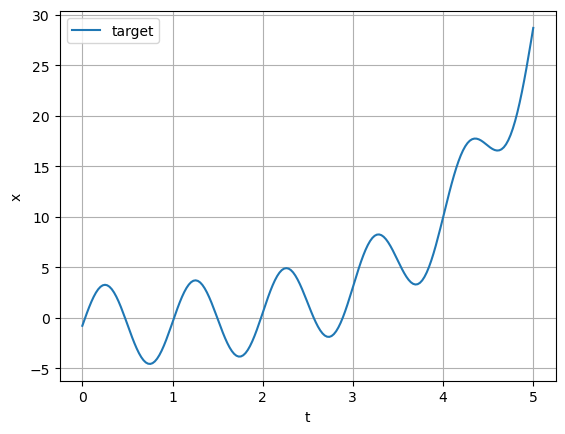

In [6]:
#  plot the trajectory
data = np.load("q2_b_data.npy") # size: 200*2, the first column is time input while the second column is x-coordinate.
t = data[:, 0]
target = data[:, 1]

plt.plot(t, target, label='target')
ax = plt.gca()
ax.xaxis.set_major_locator(MultipleLocator(1))  # tick interval = 1
plt.legend()
plt.grid()
plt.xlabel("t")
plt.ylabel("x")
plt.show()

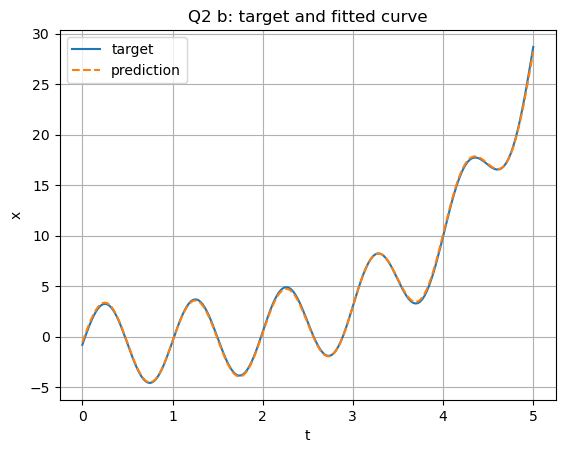

MSE: 0.016198
Justification: This curve has both a growing trend and a repeating oscillation, so a small combination of linear, exponential, sine, and cosine bases gives a simple and good fit.


In [7]:
# TODO: Write your code here.
omega = 2 * np.pi
phi = np.column_stack([
    t,
    np.exp(0.9 * t),
    np.sin(omega * t),
    np.cos(omega * t)
])
design_matrix = np.column_stack([np.ones_like(t), phi])

weights = np.linalg.lstsq(design_matrix, target, rcond=None)[0]
prediction = design_matrix @ weights
mse = np.mean((target - prediction) ** 2)

plt.figure()
plt.plot(t, target, label='target')
plt.plot(t, prediction, label='prediction', linestyle='--')
ax = plt.gca()
ax.xaxis.set_major_locator(MultipleLocator(1))
plt.grid()
plt.xlabel("t")
plt.ylabel("x")
plt.title("Q2 b: target and fitted curve")
plt.legend()
plt.show()

print(f"MSE: {mse:.6f}")
print("Justification: This curve has both a growing trend and a repeating oscillation, so a small combination of linear, exponential, sine, and cosine bases gives a simple and good fit.")


# Question 3

**Q3 a (4 marks)**

You are given a data array called "shape_array.npy" that comprises 7 samples organised as columns in the array, where each column corresponds to one sample. The data format in each column is: [x_1, y_1, z_1, x_2, y_2, z_2, ………, x_N, y_N, z_N], where (x_i, y_i, z_i) corresponds to the i-th 3D point of a blood vessel. By plotting all 3D points in one column, you can obtain the shape of a blood vessel of that sample.

Plot seven figures to show the 3D blood vessel shape for each sample separately. Also plot two arbitrary shapes on top of each other to get a feeling of how similar or dissimilar the shapes are.

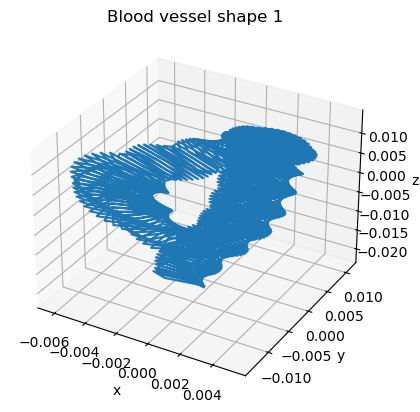

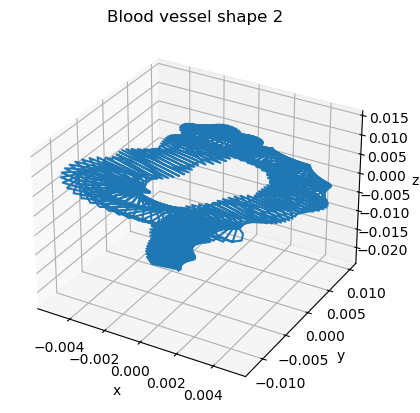

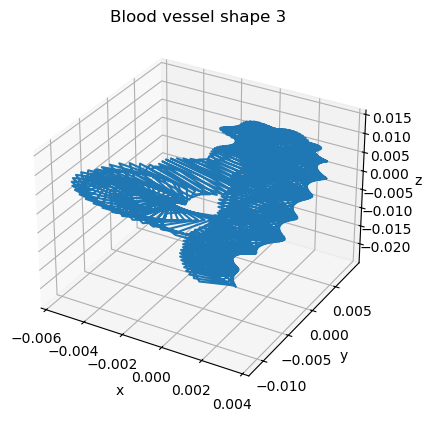

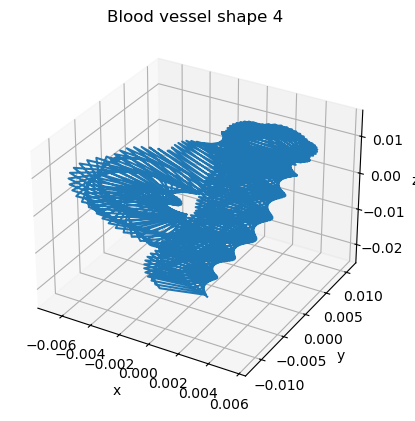

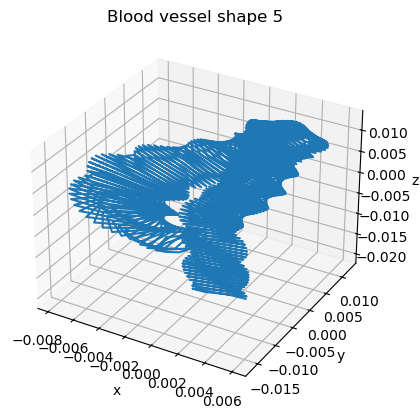

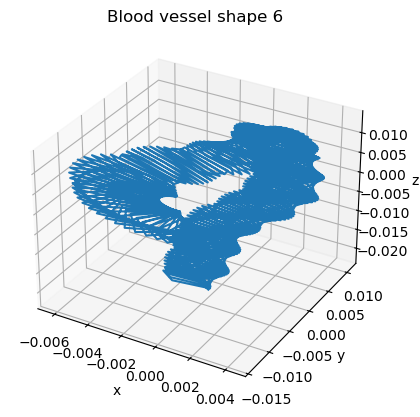

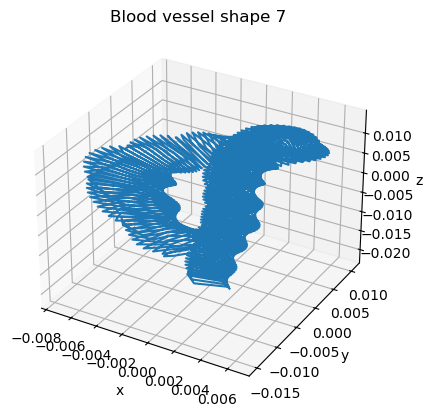

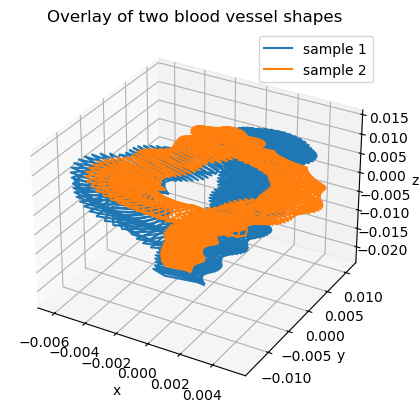

In [9]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # Import the 3D plotting toolkit

import numpy as np

# TODO: Write your code here.
shape_array = np.load("shape_array.npy")
num_points = shape_array.shape[0] // 3

def reshape_shape(sample_column):
    return sample_column.reshape(num_points, 3)

for sample_idx in range(shape_array.shape[1]):
    points = reshape_shape(shape_array[:, sample_idx])
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')
    ax.plot(points[:, 0], points[:, 1], points[:, 2])
    ax.set_title(f"Blood vessel shape {sample_idx + 1}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")

sample_1 = reshape_shape(shape_array[:, 0])
sample_2 = reshape_shape(shape_array[:, 1])
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot(sample_1[:, 0], sample_1[:, 1], sample_1[:, 2], label='sample 1')
ax.plot(sample_2[:, 0], sample_2[:, 1], sample_2[:, 2], label='sample 2')
ax.set_title("Overlay of two blood vessel shapes")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.legend()
plt.show()


**Q3 b (10 marks)** 

Next, perform eigendecomposition of the covariance matrix estimated from the given data array. Finally, project original data onto lower-dimensional space and reconstruct data.

Proceed as follows:

1. Subtract the mean from the data, so that it is centered around the origin.

2. Estimate the covariance matrix from the centred data.

3. Calculate eigenvectors and eigenvalues using numpy functions

4. Project centered data (1845 dimension) into 5 dimension. 

5. Reconstruct the blood vessel shape from the lower dimension data in step 4.


As a sanity check plot a blood vessel shape reconstructed from the eigenvectors on top of the original blood vessel shape. Comment on your results.

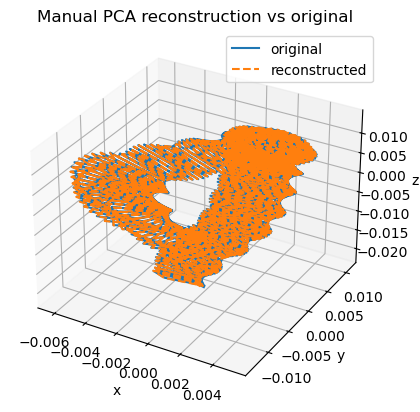

Top 5 eigenvalues: [1.13989731e-03 3.83298015e-04 1.43924451e-04 1.14435391e-04
 3.12036972e-05]
Projected data shape: (5, 7)
Reconstructed data shape: (1845, 7)
Comment: The reconstructed curve is close to the original overall shape, with some detail lost after reducing the data to 5 dimensions.


In [10]:
# TODO: Write your code here.
mean_shape = np.mean(shape_array, axis=1, keepdims=True)
centered_data = shape_array - mean_shape

covariance_matrix = np.cov(centered_data)
eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)
sorted_indices = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[sorted_indices]
eigenvectors = eigenvectors[:, sorted_indices]

projection_eigenvectors = eigenvectors[:, :5]
projected_data = projection_eigenvectors.T @ centered_data
reconstructed_data = projection_eigenvectors @ projected_data + mean_shape

original_points = reshape_shape(shape_array[:, 0])
reconstructed_points = reshape_shape(reconstructed_data[:, 0])

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot(original_points[:, 0], original_points[:, 1], original_points[:, 2], label='original')
ax.plot(reconstructed_points[:, 0], reconstructed_points[:, 1], reconstructed_points[:, 2], label='reconstructed', linestyle='--')
ax.set_title("Manual PCA reconstruction vs original")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.legend()
plt.show()

print("Top 5 eigenvalues:", eigenvalues[:5])
print("Projected data shape:", projected_data.shape)
print("Reconstructed data shape:", reconstructed_data.shape)
print("Comment: The reconstructed curve is close to the original overall shape, with some detail lost after reducing the data to 5 dimensions.")


**Q3 c (4 marks)** 

Research PCA analysis using the *scikit-learn* library. Perform PCA analysis and show the reconstructed data of any blood vessel shape on top of the original blood vessel shape. There are variables in the PCA object that correspond to the eigenvalues used for choosing projection eigenvectors. Compare the eigenvalues  and eigenvectors you have computed in the previous question with the eigenvalues  and the eigenvectors computed by the *scikit-learn* library. Compare the reconstructed coordinates from both methods. Comment on your results.

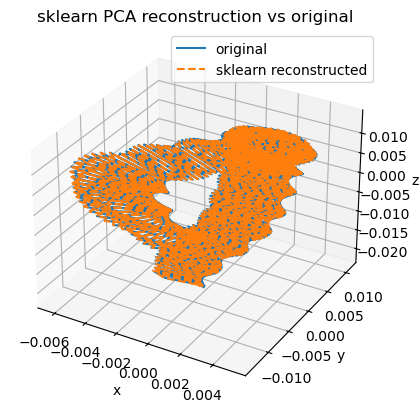

Manual top 5 eigenvalues: [1.13989731e-03 3.83298015e-04 1.43924451e-04 1.14435391e-04
 3.12036972e-05]
sklearn top 5 eigenvalues: [1.13989681e-03 3.83297709e-04 1.43924539e-04 1.14435396e-04
 3.12037046e-05]
Eigenvector similarity (absolute dot product): [1.00000007 0.99999999 1.00000012 1.00000007 1.00000017]
Reconstruction difference for sample 1: 1.3228151289595861e-08
Comment: The eigenvalues and reconstructions are very similar. Small differences can appear because eigenvectors can differ by sign while representing the same direction.


In [11]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # Import the 3D plotting toolkit

# TODO: Write your code here.
import numpy as np

pca = PCA(n_components=5)
shape_scores = pca.fit_transform(shape_array.T)
sklearn_reconstructed_data = pca.inverse_transform(shape_scores).T

original_points = reshape_shape(shape_array[:, 0])
sklearn_reconstructed_points = reshape_shape(sklearn_reconstructed_data[:, 0])

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot(original_points[:, 0], original_points[:, 1], original_points[:, 2], label='original')
ax.plot(sklearn_reconstructed_points[:, 0], sklearn_reconstructed_points[:, 1], sklearn_reconstructed_points[:, 2], label='sklearn reconstructed', linestyle='--')
ax.set_title("sklearn PCA reconstruction vs original")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.legend()
plt.show()

sklearn_eigenvalues = pca.explained_variance_
sklearn_eigenvectors = pca.components_.T
manual_top5 = eigenvalues[:5]
manual_vectors = projection_eigenvectors
eigenvector_similarity = np.abs(np.sum(manual_vectors * sklearn_eigenvectors, axis=0))
reconstruction_difference = np.linalg.norm(reconstructed_data[:, 0] - sklearn_reconstructed_data[:, 0])

print("Manual top 5 eigenvalues:", manual_top5)
print("sklearn top 5 eigenvalues:", sklearn_eigenvalues)
print("Eigenvector similarity (absolute dot product):", eigenvector_similarity)
print("Reconstruction difference for sample 1:", reconstruction_difference)
print("Comment: The eigenvalues and reconstructions are very similar. Small differences can appear because eigenvectors can differ by sign while representing the same direction.")
